# 07-01 - Three Networks of One Town

You load Princeton's three street networks, work shortest paths by hand and across town, and read centrality and form off the graphs.

First the three graphs and their intersections. Then seven places by hand, Nassau Hall to the Dinky by edges and by metres, more than one path, what three searches settle, and all pairs with Brandes' counting. Then betweenness by car and on foot, and the form of three towns. At the end you change the network type.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mob_tools as mob

plt.rcParams["figure.dpi"] = 72

scene = json.load(open("data/scene.json"))
reference = json.load(open("data/ground_truth.json"))["p07"]
rules, anchors, lecture = scene["rules"], scene["anchors"], scene["lecture"]
print(f"Princeton's networks of {scene['snapshot']['graphs']} through osmnx {scene['snapshot']['osmnx']} in "
      f"{scene['crs']}; the specimen {reference['traces']['kp2']['fixes']:,} fixes; the stay rule "
      f"{rules['stay']['dist_m']:g} m and {rules['stay']['min_s'] / 60:g} minutes; the class's counts are "
      f"{'published' if reference['class_traces']['published'] else 'not published yet'}")

Princeton's networks of 2026-10-30 through osmnx 2.1.1 in EPSG:26918; the specimen 8,918 fixes; the stay rule 50 m and 10 minutes; the class's counts are not published yet


## Three graphs of one town

The cell loads the three networks the lecture took from OpenStreetMap, counts their nodes, edges and street kilometres beside the reference, and draws them.

drive   932 nodes,  2,442 edges,  242 km   reference 932 / 2,442 / 242
bike  3,167 nodes,  7,907 edges,  411 km   reference 3,167 / 7,907 / 411
walk  6,814 nodes, 19,922 edges,  608 km   reference 6,814 / 19,922 / 608


the walk graph has 7.3 times the drive graph's nodes   reference 7.3


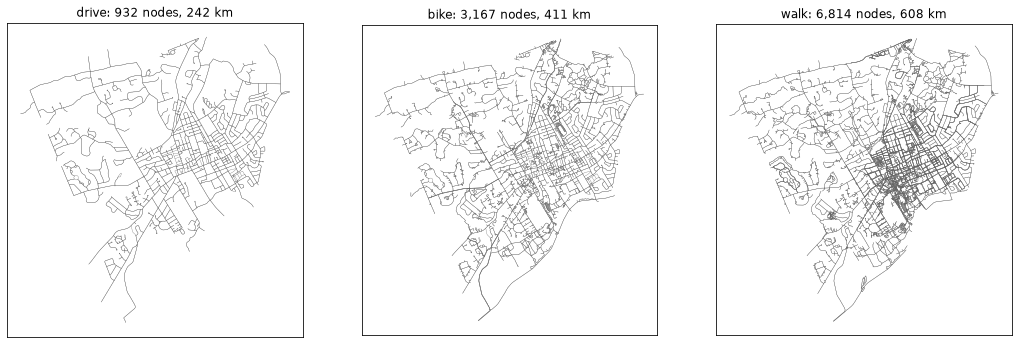

In [2]:
G = {m: mob.load_graph(f"data/princeton_{m}.graphml") for m in ("drive", "bike", "walk")}
stats = {m: mob.basic_stats(g) for m, g in G.items()}
fig, axes = plt.subplots(1, 3, figsize=(18, 7), subplot_kw={"xticks": [], "yticks": []})
for ax, (m, g) in zip(axes, G.items()):
    km, ref = stats[m]["street_length_total"] / 1000, reference["graphs"][m]
    print(f"{m:5s} {g.number_of_nodes():>5,} nodes, {g.number_of_edges():>6,} edges, {km:4.0f} km"
          f"   reference {ref['nodes']:,} / {ref['edges']:,} / {ref['km']:.0f}")
    mob.show_graph(g, ax, lw=0.3)
    ax.set_title(f"{m}: {g.number_of_nodes():,} nodes, {km:.0f} km")
ratio = G["walk"].number_of_nodes() / G["drive"].number_of_nodes()
print(f"the walk graph has {ratio:.1f} times the drive graph's nodes   "
      f"reference {reference['graphs']['walk_drive_ratio']:.1f}")

Three filters on one map. The drive network keeps the streets a car may use, the bike network adds cycleways and the streets where cycling is allowed, and the walk network keeps footways, paths, steps and streets with a sidewalk. The walk graph has 7.3 times the nodes of the drive graph because the campus and the parks are full of paths no car enters. A node is an intersection or a dead end, an edge the street between two, measured along its curve. Every number inherits the type.

## Intersections by their number of streets

The cell prints the shares of dead ends, three-way and four-way crossings on each network, counting streets per node as OSMnx does, and maps the drive network's nodes.

drive dead ends 14%, three-way 73%, four-way 12%   reference 14%, 73%, 12%
bike  dead ends 21%, three-way 69%, four-way 9%   reference 21%, 69%, 9%
walk  dead ends 17%, three-way 57%, four-way 26%   reference 17%, 57%, 26%


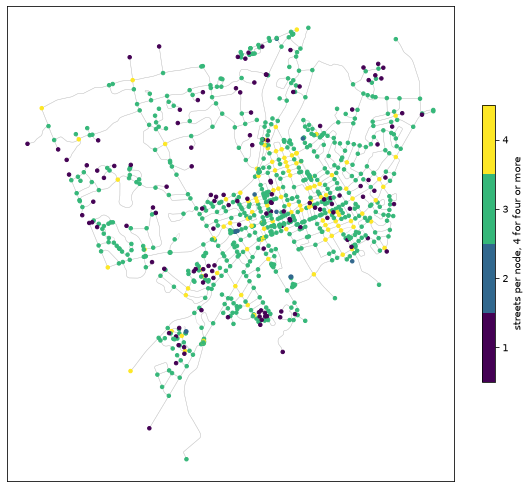

In [3]:
for m in G:
    per_node, ref = stats[m]["streets_per_node_proportions"], reference["graphs"][m]
    print(f"{m:5s} dead ends {per_node[1]:.0%}, three-way {per_node[3]:.0%}, four-way {per_node[4]:.0%}"
          f"   reference {ref['dead_end_share']:.0%}, {ref['three_way_share']:.0%}, "
          f"{ref['four_way_share']:.0%}")
drive_xy = mob.node_xy(G["drive"]).assign(streets=pd.Series(dict(G["drive"].nodes(data="street_count"))))
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"xticks": [], "yticks": []})
mob.show_graph(G["drive"], ax, colour="#cccccc", lw=0.4)
dots = ax.scatter(drive_xy["x"], drive_xy["y"], c=drive_xy["streets"].clip(upper=4), s=12, zorder=3,
                  cmap=plt.get_cmap("viridis", 4), vmin=0.5, vmax=4.5)
fig.colorbar(dots, ax=ax, shrink=0.5, ticks=[1, 2, 3, 4]).set_label("streets per node, 4 for four or more")

OSMnx counts the physical streets that meet at a node, whatever their direction of travel. By car 14 percent of the nodes are dead ends, 73 percent three-way junctions and 12 percent four-way crossings, and on foot 26 percent are four-way. The map reads the century a neighbourhood was laid out in. Four-way crossings are the grid of the eighteenth and nineteenth century town, downtown and along Nassau Street. Three-way junctions and dead ends are the suburb of the twentieth century.

## Seven places by hand

The cell builds the lecture's toy, seven places and nine edges in hundreds of metres, runs Dijkstra's method from A round by round and counts edges by breadth-first search.

In [4]:
toy = mob.graph_from_edges(lecture["toy"]["edges"], lecture["toy"]["layout"], unit=lecture["toy"]["unit_m"])
steps, rt = mob.dijkstra_steps(toy, "A"), reference["toy"]
rounds = pd.DataFrame([r["tentative"] for r in steps["rounds"]], index=steps["order"]).rename_axis("settles")
print(rounds.fillna(np.inf).to_string(float_format="{:.0f}".format))
print(f"{steps['checks']} checks, {steps['improvements']} improvements, predecessors of B to G "
      f"{', '.join(steps['pred'][n] for n in 'BCDEFG')}   reference {rt['checks']}, {rt['improvements']}, "
      f"{', '.join(rt['pred'][n] for n in 'BCDEFG')}")
bfs, paths_ag = mob.fewest_edges_path(toy, "A", "G"), mob.k_shortest_paths(toy, "A", "G", k=100)
print(f"edges from A {bfs['hops']}   reference {rt['hops_from_A']}")
print(f"{len(paths_ag)} simple paths from A to G; fewest edges {bfs['path']}, {bfs['length']:.0f} m"
      f"   reference {rt['simple_paths_AG']}; {rt['fewest_AG']['path']}, {rt['fewest_AG']['length_m']:.0f} m")

         A   B   C   D   E   F   G
settles                           
A        0 200 300 inf inf inf inf
B        0 200 300 500 inf inf inf
C        0 200 300 500 500 inf inf
D        0 200 300 500 500 800 inf
E        0 200 300 500 500 800 900
F        0 200 300 500 500 800 900
G        0 200 300 500 500 800 900
18 checks, 6 improvements, predecessors of B to G A, A, B, C, D, E   reference 18, 6, A, A, B, C, D, E
edges from A {'A': 0, 'B': 1, 'C': 1, 'D': 2, 'E': 2, 'F': 3, 'G': 3}   reference {'A': 0, 'B': 1, 'C': 1, 'D': 2, 'E': 2, 'F': 3, 'G': 3}
8 simple paths from A to G; fewest edges ['A', 'C', 'E', 'G'], 900 m   reference 8; ['A', 'C', 'E', 'G'], 900 m


Each row is one round, which settles the unsettled node of least tentative distance and relaxes its edges, lowering a neighbour's distance when the route through the settled node is shorter. The last row reads 0, 200, 300, 500, 500, 800 and 900 m from A after 18 checks and 6 improvements, and the predecessors trace every shortest path. Breadth-first search counts edges instead, ring by ring. Of the eight simple paths from A to G, the one through C and E has the fewest edges and the fewest metres.

## Fewest edges against fewest metres

The cell finds Nassau Hall and the Dinky station on the walk network and compares the path of fewest edges, the path of fewest metres and the straight line.

In [5]:
walk = G["walk"]
stations = gpd.read_file("data/layers.gpkg", layer="destinations").query("category == 'station'")
dinky = stations[stations["name"] == "Princeton"].geometry.iloc[0]
hall = (anchors["nassau_hall"]["x"], anchors["nassau_hall"]["y"])
source, target = mob.nearest_nodes(walk, *hall), mob.nearest_nodes(walk, dinky.x, dinky.y)
hops, best = mob.fewest_edges_path(walk, source, target), mob.search(walk, source, target)
straight, rr, rc = np.hypot(dinky.x - hall[0], dinky.y - hall[1]), reference["routing"], reference["circuity"]
print(f"by edges  {hops['edges']} edges, {hops['length']:,.0f} m; by metres {len(best['path']) - 1} edges, "
      f"{best['distance']:,.0f} m; straight {straight:.0f} m, circuity {best['distance'] / straight:.2f}")
print(f"reference {rr['fewest_edges']['edges']} edges, {rr['fewest_edges']['length_m']:,.0f} m; by metres "
      f"{rr['shortest']['edges']} edges, {rr['shortest']['length_m']:,.0f} m; "
      f"straight {rc['straight_m']:.0f} m, circuity {rc['circuity']:.2f}")

by edges  25 edges, 1,013 m; by metres 32 edges, 854 m; straight 737 m, circuity 1.16
reference 25 edges, 1,013 m; by metres 32 edges, 854 m; straight 737 m, circuity 1.16


Two questions, two answers. Breadth-first search finds 25 edges and 1,013 m, Dijkstra's method 32 edges and 854 m, because the short way crosses the campus on many short footpaths. The straight line is 737 m, so the circuity, network length over straight line, is 1.16, and its inverse for a single trip is the directness of 07-03. Every street is at least as long as the straight line between its ends, so the straight line is a lower bound on any distance along the network.

## More than one path

The cell lists the 50 shortest simple paths to the Dinky by Yen's method and builds a real alternative by forbidding every edge of the first.

In [6]:
paths, ry = pd.DataFrame(mob.k_shortest_paths(walk, source, target, k=50)), rr["yen"]
spread, distinct = np.ptp(paths["length"]), sum(paths["shared"] <= 0.8)
alt, ra = mob.dissimilar_alternative(walk, best["path"]), rr["alternative"]
print(f"{len(paths)} shortest paths within {spread:.0f} m, {distinct} sharing at most 80 percent with the "
      f"first, the alternative {alt['length']:.0f} m sharing {alt['shared']:.0%}")
print(f"reference {ry['k']} within {ry['spread_m']:.0f} m, {ry['at_or_under_80']} sharing "
      f"at most 80 percent with the first, the alternative {ra['length_m']:.0f} m sharing {ra['shared']:.0%}")
print(paths[["length", "shared"]].head(8).round(2).to_string())

50 shortest paths within 9 m, 8 sharing at most 80 percent with the first, the alternative 945 m sharing 0%
reference 50 within 9 m, 8 sharing at most 80 percent with the first, the alternative 945 m sharing 0%
   length  shared
0  854.36    1.00
1  855.24    0.93
2  855.68    0.98
3  856.56    0.91
4  856.64    0.93
5  856.69    0.93
6  857.37    0.96
7  857.96    0.91


The 50 shortest paths lie within 9 m of each other, and all but 8 share more than 80 percent of their length with the first. They are the same route with a corner cut differently, so a router that offers a choice must build one that differs, here by forbidding the first path's edges, which gives 945 m sharing nothing. The shortest path is also a weak model of a person. In Minneapolis, 143 tracked drivers took the shortest-time path on about a third of their trips.

## The lie of the circle

The cell draws the path of fewest edges, the path of fewest metres, the alternative and the straight line over the walk network between Nassau Hall and the Dinky.

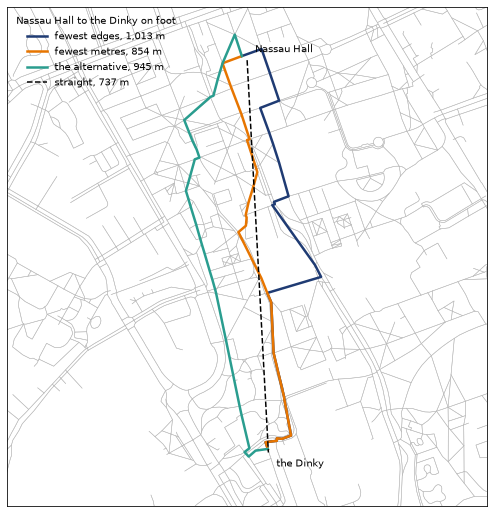

In [7]:
xy = mob.node_xy(walk)
by_edges, route, other = xy.loc[hops["path"]], xy.loc[best["path"]], xy.loc[alt["path"]]
fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={"xticks": [], "yticks": []})
mob.show_graph(walk, ax, colour="#bbbbbb", lw=0.5)
ax.plot(by_edges["x"], by_edges["y"], color="#1f3b73", lw=2.5, label=f"fewest edges, {hops['length']:,.0f} m")
ax.plot(route["x"], route["y"], color="#e77500", lw=2.5, label=f"fewest metres, {best['distance']:,.0f} m")
ax.plot(other["x"], other["y"], color="#2a9d8f", lw=2.5, label=f"the alternative, {alt['length']:,.0f} m")
ax.plot([hall[0], dinky.x], [hall[1], dinky.y], "k--", lw=1.5, label=f"straight, {straight:.0f} m")
ax.annotate("Nassau Hall", hall, xytext=(8, 8), textcoords="offset points")
ax.annotate("the Dinky", (dinky.x, dinky.y), xytext=(8, -14), textcoords="offset points")
ax.set(xlim=(hall[0] - 450, hall[0] + 450), ylim=(dinky.y - 100, hall[1] + 100))
ax.legend(frameon=False, loc="upper left").set_title("Nassau Hall to the Dinky on foot")

Blue takes the fewest edges, orange the fewest metres and green the alternative, while the grey lines are every path the walk network knows in the window. The dashed line ignores the network, and the circuity of 1.16 measures by how much a circle lies. Every isochrone of 07-02 is this picture repeated from one point in every direction with a budget, which is why an isochrone is never a circle. If a path takes an odd turn, the network lacks a link where you expect one.

## What Dijkstra and A* settle

The cell runs Dijkstra's method and A*, guided by the straight line to the Dinky, and counts the nodes each settles and the pushes onto its heap.

In [8]:
guide = mob.straight_line_heuristic(walk, target)
astar = mob.search(walk, source, target, heuristic=guide)
print(f"Dijkstra settles {len(best['settled']):,} of {walk.number_of_nodes():,} nodes "
      f"after {best['pushes']:,} pushes   reference {rr['dijkstra']['settled']:,} after "
      f"{rr['dijkstra']['pushes']:,}")
print(f"A* settles {len(astar['settled'])} after {astar['pushes']} pushes with {astar['reopened']} reopened, "
      f"{astar['distance']:.0f} m   reference {rr['astar']['settled']} after {rr['astar']['pushes']} with "
      f"{rr['astar']['reopened']} reopened, {rr['astar']['length_m']:.0f} m")
print(f"the guide: {guide.short_edges:,} edges shorter than their chord, by up to {guide.short_by_m:.2f} m"
      f"   reference {rr['astar']['short_edges']:,}, {rr['astar']['short_by_m']:.2f} m")

Dijkstra settles 1,625 of 6,814 nodes after 2,051 pushes   reference 1,625 after 2,051
A* settles 290 after 420 pushes with 0 reopened, 854 m   reference 290 after 420 with 0 reopened, 854 m
the guide: 4,640 edges shorter than their chord, by up to 0.98 m   reference 4,640, 0.98 m


A push puts a node on the heap, and settling takes it off for good. Dijkstra's method is blind and settles rings of growing distance in every direction until one reaches the Dinky, 1,625 of 6,814 nodes. A* settles by the distance so far plus the straight line still to go and needs 290 for the same 854 m. On 4,640 edges the stored length, measured on the sphere, falls short of the chord on the map by at most 0.98 m, so A*'s guarantee holds to within a metre.

## The search from both ends

The cell runs Dijkstra's method from both ends at once and marks the nodes each of the three searches settled around the shortest walk.

from both ends 404 and 404 settled, 854 m   reference 404 and 404, 854 m


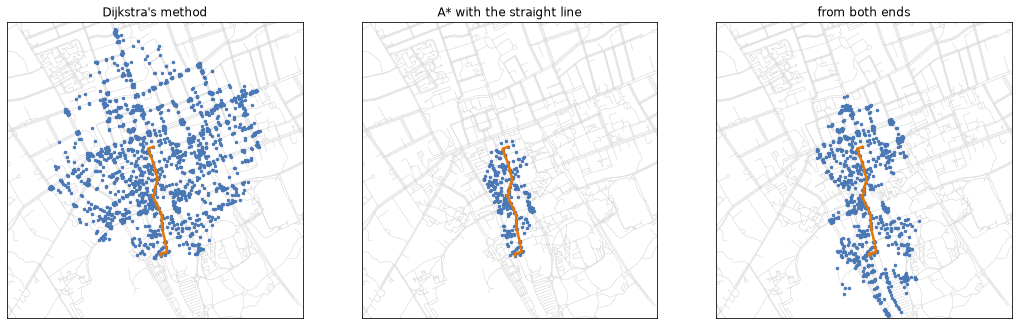

In [9]:
ends = mob.bidirectional_search(walk, source, target)
print(f"from both ends {len(ends['forward'])} and {len(ends['backward'])} settled, {ends['distance']:.0f} m"
      f"   reference {rr['bidirectional']['forward']} and {rr['bidirectional']['backward']}, "
      f"{rr['bidirectional']['length_m']:.0f} m")
runs = {"Dijkstra's method": best["settled"], "A* with the straight line": astar["settled"],
        "from both ends": ends["forward"] + ends["backward"]}
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), subplot_kw={"xticks": [], "yticks": []})
for ax, (name, settled) in zip(axes, runs.items()):
    mob.show_graph(walk, ax, colour="#dddddd", lw=0.4)
    ax.scatter(xy.loc[settled, "x"], xy.loc[settled, "y"], s=6, color="#4a78b5", zorder=3)
    ax.plot(route["x"], route["y"], color="#e77500", lw=2.5, zorder=4)
    ax.set(xlim=(hall[0] - 1000, hall[0] + 1000), ylim=(hall[1] - 1150, hall[1] + 850), title=name)

Dijkstra's method settles a disc around Nassau Hall whose radius is the walk to the Dinky, and two in five of its nodes lie north of Nassau Hall, away from the station. A* bends the search into a corridor along the route. The search from both ends grows two discs of about half the radius, one around each end, and stops after 404 and 404, because two small discs hold fewer nodes than one large one. All three find 854 m.

## All pairs, shortcuts and Brandes' counting

The cell prices every distance on the walk graph two ways, contracts the toy into a hierarchy with shortcuts, and counts D's betweenness one source at a time.

In [10]:
cost = mob.all_pairs_cost(walk.number_of_nodes(), walk.number_of_edges())
print(f"all pairs on the walk graph, {cost['dijkstra']:.2g} steps by Dijkstra from every node, "
      f"{cost['floyd_warshall']:.2g} by Floyd and Warshall's triple loop")
ch = mob.contraction_hierarchy(toy, list("AFGBCDE"), source="A", target="G")
s, r, meet = ch["shortcuts"][0], rt["contraction"], ch["meetings"][0][0]
print(f"shortcut {s[1]} to {s[0]}, {s[2]:.0f} m via {s[3]} against {s[4]:.0f} m, meeting at {meet} with "
      f"{ch['distance']:.0f} m   reference {r['shortcuts'][0][2]:g} m, {r['distance_m']:g} m")
dep = {s: mob.brandes_dependencies(toy, s)["delta"]["D"] for s in toy if s != "D"}
print(f"D's dependencies {dep}, sum {sum(dep.values()):g}, halved {sum(dep.values()) / 2:g}, "
      f"{sum(dep.values()) / 2 / 15:.2f} of the 15 pairs")
print(f"reference {rt['brandes_D']['by_source']}, sum {rt['brandes_D']['total']:g}, "
      f"halved {rt['brandes_D']['half']:g}, {rt['betweenness']['D']:.2f} of the 15 pairs")

all pairs on the walk graph, 2.3e+09 steps by Dijkstra from every node, 3.2e+11 by Floyd and Warshall's triple loop
shortcut D to G, 500 m via F against 600 m, meeting at E with 900 m   reference 500 m, 900 m
D's dependencies {'A': 1.0, 'B': 1.5, 'C': 1.0, 'E': 1.0, 'F': 4.0, 'G': 0.5}, sum 9, halved 4.5, 0.30 of the 15 pairs
reference {'A': 1.0, 'B': 1.5, 'C': 1.0, 'E': 1.0, 'F': 4.0, 'G': 0.5}, sum 9, halved 4.5, 0.30 of the 15 pairs


A run of Dijkstra's method from every node costs about 2.3 billion steps on the walk graph against 320 billion for the triple loop of Floyd and Warshall. Contracting the toy in the order A, F, G, B, C, D, E needs one shortcut, D to G of 500 m through F, because the only other way is 600 m, and the upward searches from A and G meet at E with 900. Brandes' runs also count paths. D's dependencies sum to 9, halved to 4.5 of 15 pairs, 0.30.

## Betweenness by car

The cell computes the betweenness of every intersection and every street segment of the drive network, exact, ranks the streets by their most central segment and draws the map.

by car    Nassau Street 0.21, Mount Lucas Road 0.14, Stockton Street 0.14, University Place 0.13, Chambers Street 0.13
reference Nassau Street 0.21, Mount Lucas Road 0.14, Stockton Street 0.14, University Place 0.13, Chambers Street 0.13
the most central intersection 0.21   reference 0.21


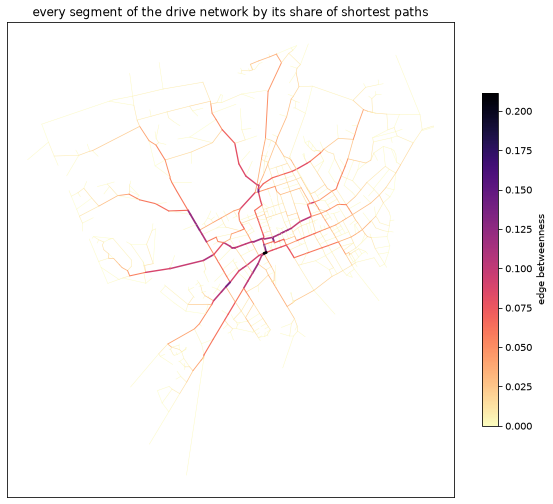

In [11]:
drive_nodes, drive_edges = mob.centrality(G["drive"])
by_car = mob.edge_names(G["drive"], drive_edges)
print("by car    " + ", ".join(f"{n} {v:.2f}" for n, v in mob.top_streets(by_car)[:5]))
print("reference " + ", ".join(f"{n} {v:.2f}" for n, v in reference["centrality"]["top_streets"][:5]))
print(f"the most central intersection {drive_nodes['betweenness'].max():.2f}   "
      f"reference {reference['centrality']['max_node_betweenness']:.2f}")
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"xticks": [], "yticks": []})
car_lines = mob.show_edges(by_car, ax, colour_by="betweenness", cmap="magma_r", lw=0.4)
ax.set_title("every segment of the drive network by its share of shortest paths")
fig.colorbar(car_lines, ax=ax, shrink=0.6).set_label("edge betweenness")

Betweenness is the share of all shortest paths between pairs of other nodes that pass through a node or an edge, a tie giving a fraction, computed here by one pass of Brandes' algorithm from each of the 932 intersections. Nassau Street carries 21 percent, then Mount Lucas Road and Stockton Street, and the most central intersection about as much. The lake and the railway leave few crossings between the north and the south, and whatever crosses carries the paths. Betweenness detects bridges and bottlenecks, not traffic.

## On foot, the lecture's map

The cell reads the betweenness of the walk network as the lecture computed it, exactly, one pass from every one of its 6,814 nodes, which takes minutes, and draws it.

on foot   Greenview Avenue 0.09, Nassau Street 0.08, Wiggins Street 0.08, North Tulane Street 0.08, Walnut Lane 0.08
reference Greenview Avenue 0.09, Nassau Street 0.08, Wiggins Street 0.08, North Tulane Street 0.08, Walnut Lane 0.08, exact from all 6,814 sources
the top segment 0.10, unnamed, 51 of the top 100 unnamed   reference 0.10, unnamed, 51


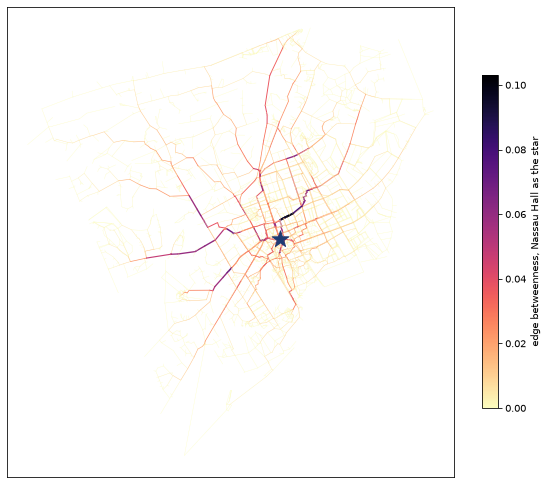

In [12]:
walk_tab = pd.read_csv("data/centrality_walk.csv.gz")
on_foot, unnamed = reference["centrality"]["walk"], walk_tab.nlargest(100, "betweenness")["name"].isna()
print("on foot   " + ", ".join(f"{n} {v:.2f}" for n, v in mob.top_streets(walk_tab)[:5]))
print("reference " + ", ".join(f"{n} {v:.2f}" for n, v in on_foot["top_streets"][:5])
      + f", exact from all {on_foot['sources']:,} sources")
print(f"the top segment {walk_tab['betweenness'].max():.2f}, {'unnamed' if unnamed.iloc[0] else 'named'}, "
      f"{unnamed.sum()} of the top 100 unnamed   reference {on_foot['top_segment']:.2f}, "
      f"{'named' if on_foot['top_segment_named'] else 'unnamed'}, {on_foot['unnamed_in_top_100']}")
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"xticks": [], "yticks": []})
foot_lines = mob.show_edges(walk_tab, ax, colour_by="betweenness", cmap="magma_r", lw=0.3)
ax.scatter(*hall, marker="*", s=300, color="#1f3b73", zorder=5)
fig.colorbar(foot_lines, ax=ax, shrink=0.6).set_label("edge betweenness, Nassau Hall as the star")

On foot the most central named streets are Greenview Avenue at 0.09, then Nassau Street and Wiggins Street at 0.08. The top segment, 0.10, carries no name. It is a footway about half a kilometre north of Nassau Hall, the star, and 51 of the 100 most central segments are unnamed footways, steps and service roads, so a ranking by street name misses half of where the shortest walks run. Two maps, two answers to one question, and the network type chose between them.

## Street orientation in three towns

The cell bins the compass bearing of every street segment of three drive networks into 36 bins and computes the entropy and the order of each rose.

princeton entropy 3.35 nats, order 0.20   reference 3.35, 0.20
trenton   entropy 3.48 nats, order 0.09   reference 3.48, 0.09
hopewell  entropy 2.66 nats, order 0.66   reference 2.66, 0.66


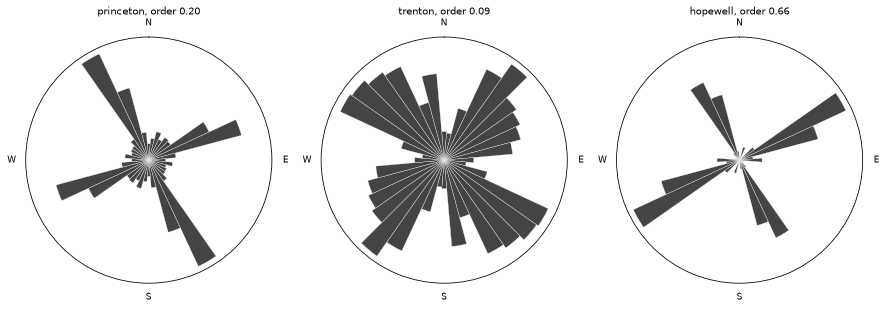

In [13]:
towns = {"princeton": G["drive"], "trenton": mob.load_graph("data/trenton_drive.graphml"),
         "hopewell": mob.load_graph("data/hopewell_drive.graphml")}
fig, axes = plt.subplots(1, 3, figsize=(15, 5), subplot_kw={"projection": "polar"})
for ax, (place, g) in zip(axes, towns.items()):
    rose, town_ref = mob.orientation(g), reference["towns"][place]
    print(f"{place:9s} entropy {rose['entropy']:.2f} nats, order {rose['order']:.2f}   "
          f"reference {town_ref['entropy']:.2f}, {town_ref['order']:.2f}")
    mob.show_orientation(rose["counts"], ax, title=f"{place}, order {rose['order']:.2f}", fontsize=9)

A perfect grid puts every segment and its reverse into four bins, and a web of winding streets spreads them evenly. The entropy of bin shares measures the spread, at most 3.58 nats and 1.39 for a grid, and the order index rescales it so that a grid reads 1 and a uniform spread 0. Hopewell Borough, one grid, reads 0.66, Princeton, a grid downtown and a tree beyond it, 0.20. Trenton reads 0.09 because its grids stand at different angles, which the entropy cannot tell from no grid.

## The indicators of urban form

The cell computes five of OSMnx's indicators for each town over its own area and prints them beside the reference.

In [14]:
for place, g in towns.items():
    form, town_ref = mob.basic_stats(g, lecture["towns"][place]["area_km2"] * 1e6), reference["towns"][place]
    per_node = form["streets_per_node_proportions"]
    print(f"{place:9s} intersections per km2 {form['intersection_density_km']:3.0f}, segment length "
          f"{form['street_length_avg']:3.0f} m, circuity {form['circuity_avg']:.2f}, "
          f"dead ends {per_node[1]:.2f}, four-way {per_node[4]:.2f}")
    print(f"reference intersections per km2 {town_ref['intersection_density_km']:3.0f}, segment length "
          f"{town_ref['segment_m']:3.0f} m, circuity {town_ref['circuity']:.2f}, dead ends "
          f"{town_ref['dead_end_share']:.2f}, four-way {town_ref['four_way_share']:.2f}")

princeton intersections per km2  17, segment length 186 m, circuity 1.11, dead ends 0.14, four-way 0.12
reference intersections per km2  17, segment length 186 m, circuity 1.11, dead ends 0.14, four-way 0.12
trenton   intersections per km2  76, segment length 121 m, circuity 1.03, dead ends 0.06, four-way 0.28
reference intersections per km2  76, segment length 121 m, circuity 1.03, dead ends 0.06, four-way 0.28


hopewell  intersections per km2  33, segment length 172 m, circuity 1.04, dead ends 0.22, four-way 0.13
reference intersections per km2  33, segment length 172 m, circuity 1.04, dead ends 0.22, four-way 0.13


Trenton packs 76 intersections into a square kilometre, Hopewell Borough 33 and Princeton 17, with segments of 186 m on average against Trenton's 121. OSMnx's circuity divides the summed length of the segments by the summed straight lines between their ends, 1.11 for Princeton. Hopewell Borough has the most dead ends and Trenton the most four-way crossings. The same indicators exist for 8,914 urban areas of the world, so a town can be placed among them.

## Your turn

The betweenness above ran on the drive network. Run it on the bike network, whose graph adds the cycleways and the streets a bicycle may use, and read the top five streets again. The cell computes the edge betweenness alone, exact, in about two seconds by car and half a minute by bicycle. Run the cell as it is, then change the marked value and run it again.

Which street is the most central by bicycle, and why does a change of network type move the answer? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

drive, exact from all 932 nodes: Nassau Street 0.21, Mount Lucas Road 0.14, Stockton Street 0.14, University Place 0.13, Chambers Street 0.13


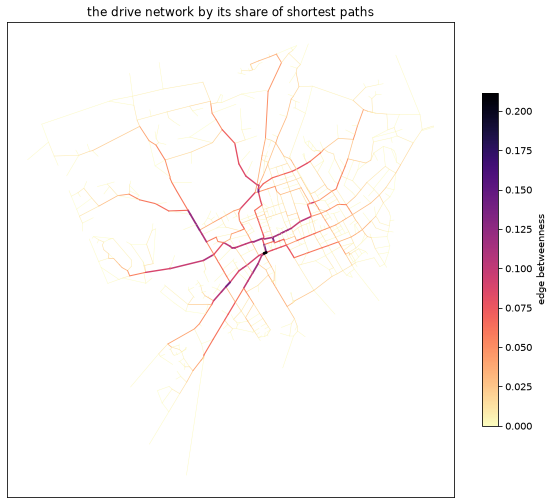

In [15]:
MODE = "drive"  # change me: "bike"
segments = mob.edge_names(G[MODE], mob.edge_betweenness(G[MODE]))
print(f"{MODE}, exact from all {G[MODE].number_of_nodes():,} nodes: "
      + ", ".join(f"{n} {v:.2f}" for n, v in mob.top_streets(segments)[:5]))
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"xticks": [], "yticks": []})
mode_lines = mob.show_edges(segments, ax, colour_by="betweenness", cmap="magma_r", lw=0.4)
ax.set_title(f"the {MODE} network by its share of shortest paths")
fig.colorbar(mode_lines, ax=ax, shrink=0.6).set_label("edge betweenness")

## Check your understanding

1. The walk graph has 7.3 times the drive graph's nodes. What did the filter keep that a car never uses, and what does it do to a shortest path?
2. A* settled 290 nodes where Dijkstra's method settled 1,625, for the same 854 m. Why is its answer still the shortest, and what would a guide that overestimates do?
3. Nassau Street carries a fifth of all shortest paths by car. Why does betweenness find bottlenecks rather than busy streets, and what weight would bring it closer to traffic?
4. Trenton was laid out as grids yet reads less ordered than Princeton. What does the entropy of bearings miss, and what would catch it?

## Where we are

You have loaded the three networks of one town and counted their intersections, worked Dijkstra's method by hand on seven places, walked from Nassau Hall to the Dinky by edges and by metres, built an alternative, compared what three searches settle, counted betweenness by car and on foot and read the form of three towns. Every number inherits the network's type, snapshot and simplification. In 07-02 the places go onto the network, and the question becomes who can reach what in fifteen minutes.

## Further resources

Nothing in this course requires anything below.

- Networks, Mark Newman, Oxford University Press 2018, second edition, chapter 8, pages 241 to 261, the algorithms for shortest paths and betweenness
- Modeling and Analyzing Urban Networks and Amenities with OSMnx, Geoff Boeing, Geographical Analysis 2025, https://doi.org/10.1111/gean.12390
- Urban spatial order: street network orientation, configuration, and entropy, Geoff Boeing, Applied Network Science 2019, https://doi.org/10.1007/s41109-019-0189-1
- Spatial Networks, A Complete Introduction, Marc Barthélemy, Springer 2022, chapters 4 and 5

The tables, numbers and this kit are the course's own work, published under CC BY 4.0. The street networks, the destinations and the isochrones derive from OpenStreetMap, licensed ODbL 1.0, copyright OpenStreetMap contributors: https://www.openstreetmap.org/copyright